In [1]:
!pip install tensorflow scikit-learn matplotlib

In [5]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Dense,
    Flatten,
    Input,
    Dropout,
    Conv2D,
    MaxPooling2D
)

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.0


In [6]:
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 26s 1us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 30s 7us/step


In [7]:
print('training images:',X_train.shape)
print('training labels:',y_train.shape)
print('test images:',X_test.shape)
print('test images:',X_test.shape)
print('test labels:',y_test.shape)

training images: (60000, 28, 28)
training labels: (60000,)
test images: (10000, 28, 28)
test images: (10000, 28, 28)
test labels: (10000,)


In [9]:
# Define class names
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]
for label, name in enumerate(class_names):
    print(label, "->", name)

0 -> T-shirt/top
1 -> Trouser
2 -> Pullover
3 -> Dress
4 -> Coat
5 -> Sandal
6 -> Shirt
7 -> Sneaker
8 -> Bag
9 -> Ankle boot


In [10]:
print(label)

9


In [11]:
print(name)

Ankle boot


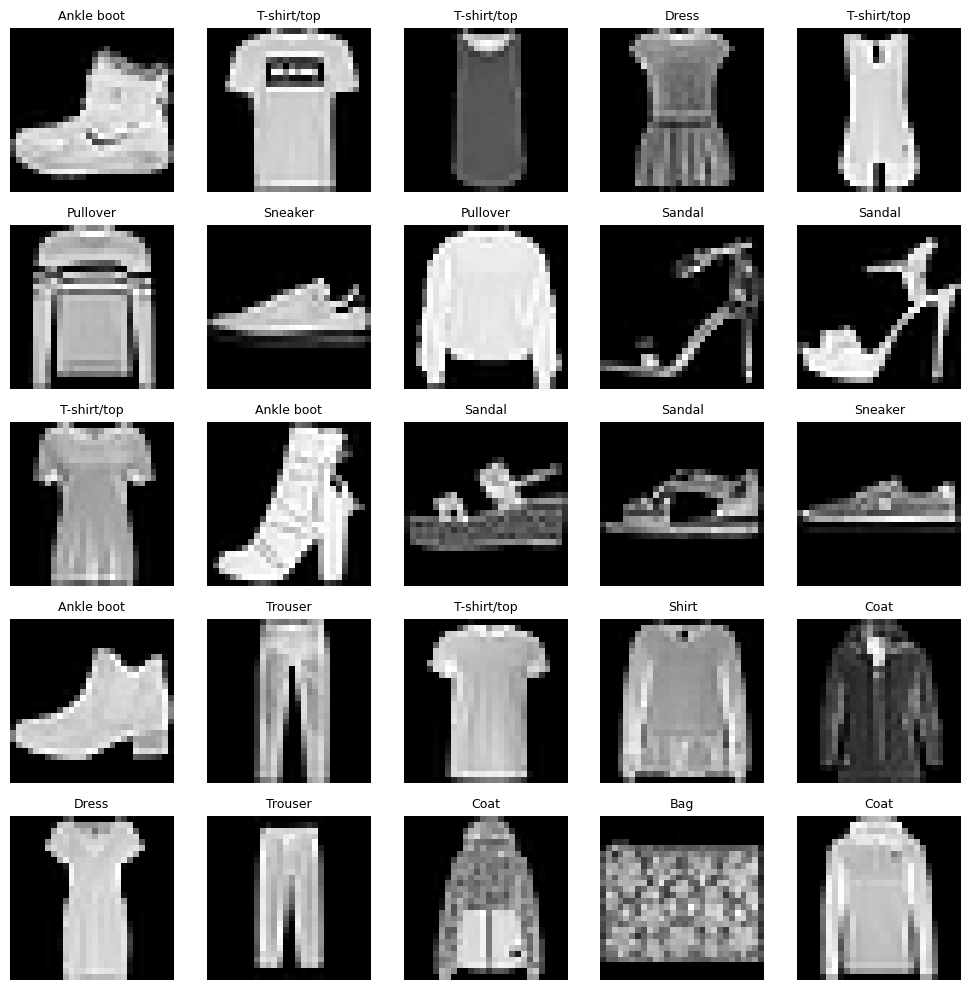

In [12]:
# View sample images
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
# Check pixel values
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())
print("Unique labels:", np.unique(y_train))

Minimum pixel value: 0
Maximum pixel value: 255
Unique labels: [0 1 2 3 4 5 6 7 8 9]


In [14]:
# Scale pixel values
X_train=X_train.astype('float32')/255.0
X_test=X_test.astype('float32')/255.0

print("New minimum:", X_train.min())
print("New maximum:", X_train.max())

New minimum: 0.0
New maximum: 1.0


In [15]:
# Build the baseline model
baseline_model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Compile the baseline model
baseline_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [17]:
# Train the baseline model
history_baseline = baseline_model.fit(
    X_train,
    y_train,
    epochs=20,
    validation_split=0.2,
    batch_size=32,
    verbose=1
)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8157 - loss: 0.5226 - val_accuracy: 0.8357 - val_loss: 0.4531
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8598 - loss: 0.3891 - val_accuracy: 0.8668 - val_loss: 0.3662
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8746 - loss: 0.3422 - val_accuracy: 0.8690 - val_loss: 0.3609
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8840 - loss: 0.3171 - val_accuracy: 0.8773 - val_loss: 0.3406
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8876 - loss: 0.3017 - val_accuracy: 0.8842 - val_loss: 0.3251
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8944 - loss: 0.2860 - val_accuracy: 0.8807 - val_loss: 0.3302
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8996 - loss: 0.2719 - val_accuracy: 0.8757 - val_loss: 0.3420
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9036 - loss: 0.2592 - 

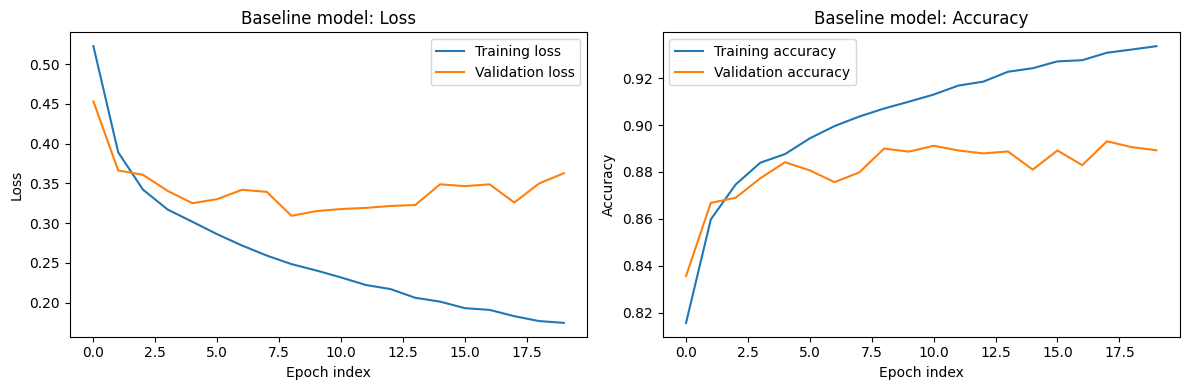

In [18]:
# Plot learning curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_baseline.history["loss"], label="Training loss")
plt.plot(history_baseline.history["val_loss"], label="Validation loss")
plt.title("Baseline model: Loss")
plt.xlabel("Epoch index")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_baseline.history["accuracy"], label="Training accuracy")
plt.plot(history_baseline.history["val_accuracy"], label="Validation accuracy")
plt.title("Baseline model: Accuracy")
plt.xlabel("Epoch index")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [19]:
# Evaluate on the test set
baseline_test_loss, baseline_test_accuracy = baseline_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Baseline test loss: {baseline_test_loss:.4f}")
print(f"Baseline test accuracy: {baseline_test_accuracy:.2%}")

Baseline test loss: 0.4010
Baseline test accuracy: 87.82%


In [20]:
# Make predictions
y_prob_baseline = baseline_model.predict(X_test, verbose=0)
y_pred_baseline = y_prob_baseline.argmax(axis=1)

print("Probability shape:", y_prob_baseline.shape)
print("Prediction shape:", y_pred_baseline.shape)

print("First prediction:", y_pred_baseline[0])
print("First actual label:", y_test[0])

Probability shape: (10000, 10)
Prediction shape: (10000,)
First prediction: 9
First actual label: 9


In [21]:
# Accuracy and classification report
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)

print(f"Accuracy: {baseline_accuracy:.2%}\n")

print(classification_report(
    y_test,
    y_pred_baseline,
    target_names=class_names,
    digits=4
))

Accuracy: 87.82%

              precision    recall  f1-score   support

 T-shirt/top     0.8082    0.8510    0.8290      1000
     Trouser     0.9979    0.9660    0.9817      1000
    Pullover     0.8021    0.7500    0.7752      1000
       Dress     0.8869    0.8940    0.8904      1000
        Coat     0.7202    0.8750    0.7901      1000
      Sandal     0.9774    0.9520    0.9645      1000
       Shirt     0.7334    0.6190    0.6714      1000
     Sneaker     0.9455    0.9540    0.9497      1000
         Bag     0.9835    0.9530    0.9680      1000
  Ankle boot     0.9444    0.9680    0.9560      1000

    accuracy                         0.8782     10000
   macro avg     0.8800    0.8782    0.8776     10000
weighted avg     0.8800    0.8782    0.8776     10000



<Figure size 1000x800 with 0 Axes>

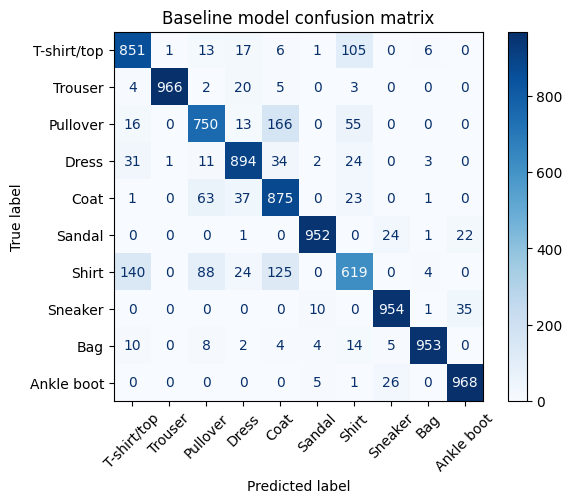

In [22]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred_baseline)

plt.figure(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    values_format="d",
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Baseline model confusion matrix")
plt.show()

Number of misclassified test images: 1218


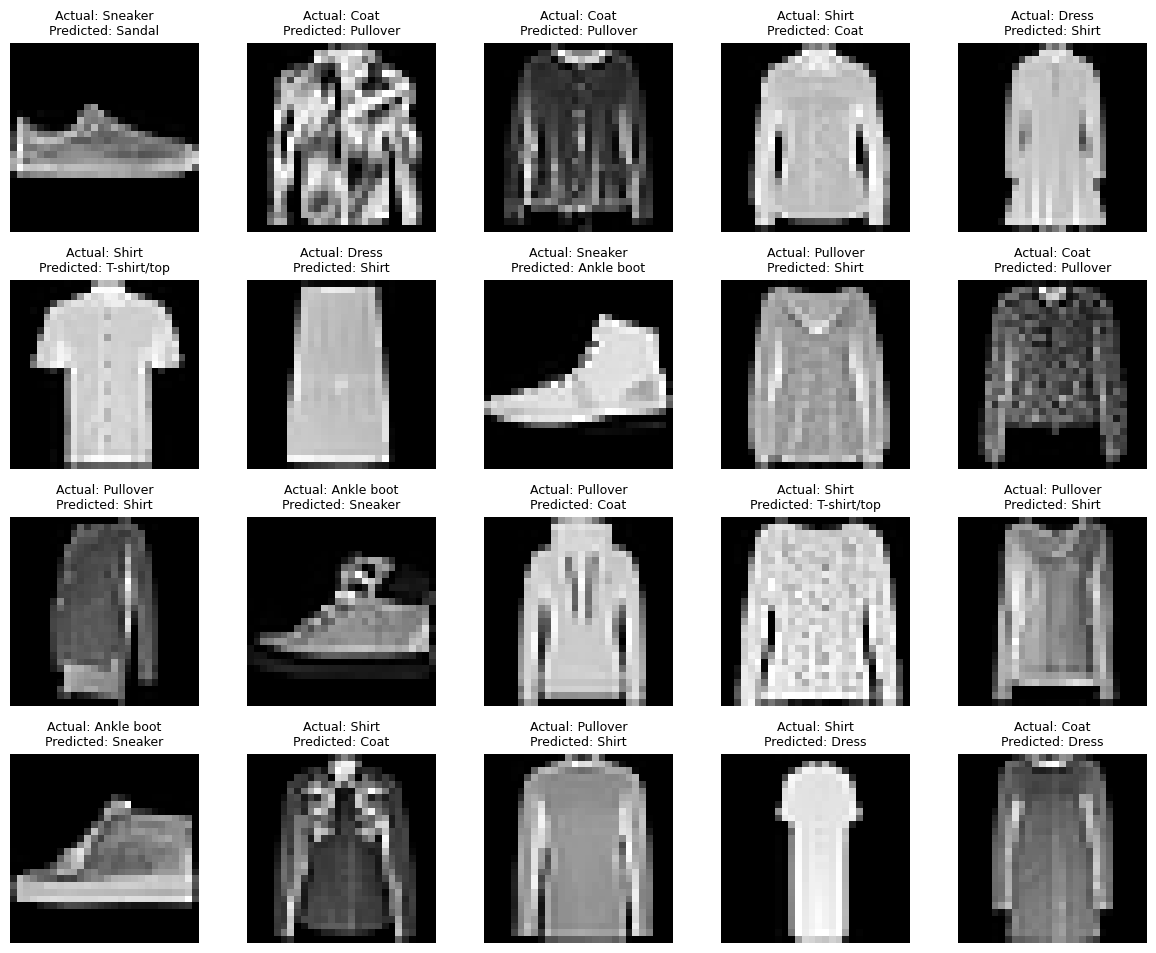

In [26]:
# Code finds every test image your model got wrong
wrong_indices = np.where(y_pred_baseline != y_test)[0]

print(f"Number of misclassified test images: {len(wrong_indices)}")

plt.figure(figsize=(12, 12))

for i, idx in enumerate(wrong_indices[:20]):
    plt.subplot(5,5, i + 1)
    plt.imshow(X_test[idx], cmap="gray")
    plt.title(
        f"Actual: {class_names[y_test[idx]]}\n"
        f"Predicted: {class_names[y_pred_baseline[idx]]}",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
# Add dropout
dropout_model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(10, activation="softmax")
])

dropout_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

dropout_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
# Train dropout model
history_dropout = dropout_model.fit(
    X_train,
    y_train,
    epochs=20,
    validation_split=0.2,
    batch_size=32,
    verbose=1
)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7706 - loss: 0.6401 - val_accuracy: 0.8370 - val_loss: 0.4471
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8325 - loss: 0.4638 - val_accuracy: 0.8547 - val_loss: 0.3906
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8471 - loss: 0.4232 - val_accuracy: 0.8578 - val_loss: 0.3833
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8551 - loss: 0.4022 - val_accuracy: 0.8717 - val_loss: 0.3534
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8596 - loss: 0.3855 - val_accuracy: 0.8628 - val_loss: 0.3628
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8644 - loss: 0.3745 - val_accuracy: 0.8757 - val_loss: 0.3380
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8659 - loss: 0.3632 - val_accuracy: 0.8748 - val_loss: 0.3365
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8683 - loss: 0.3523 - 

In [30]:
# Evaluate dropout model
dropout_test_loss, dropout_test_accuracy = dropout_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Dropout test loss: {dropout_test_loss:.4f}")
print(f"Dropout test accuracy: {dropout_test_accuracy:.2%}")

print(f"Baseline accuracy: {baseline_test_accuracy:.2%}")
print(f"Dropout accuracy: {dropout_test_accuracy:.2%}")

Dropout test loss: 0.3382
Dropout test accuracy: 88.03%
Baseline accuracy: 87.82%
Dropout accuracy: 88.03%


In [31]:
# Add early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [32]:
# Build and train early-stopping model
early_stopping_model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(10, activation="softmax")
])

early_stopping_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

history_early_stopping = early_stopping_model.fit(
    X_train,
    y_train,
    epochs=30,
    validation_split=0.2,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7755 - loss: 0.6325 - val_accuracy: 0.8438 - val_loss: 0.4317
Epoch 2/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8321 - loss: 0.4627 - val_accuracy: 0.8574 - val_loss: 0.3929
Epoch 3/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8456 - loss: 0.4255 - val_accuracy: 0.8514 - val_loss: 0.4058
Epoch 4/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8518 - loss: 0.4025 - val_accuracy: 0.8700 - val_loss: 0.3599
Epoch 5/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8571 - loss: 0.3873 - val_accuracy: 0.8674 - val_loss: 0.3539
Epoch 6/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8657 - loss: 0.3687 - val_accuracy: 0.8702 - val_loss: 0.3485
Epoch 7/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8689 - loss: 0.3583 - val_accuracy: 0.8784 - val_loss: 0.3323
Epoch 8/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8706 - loss: 0.3499 - 

In [33]:
# Evaluate early-stopping model
early_test_loss, early_test_accuracy = early_stopping_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Early-stopping test loss: {early_test_loss:.4f}")
print(f"Early-stopping test accuracy: {early_test_accuracy:.2%}")

Early-stopping test loss: 0.3491
Early-stopping test accuracy: 88.04%


In [34]:
# Build a CNN
cnn_model = Sequential([
    Input(shape=(28,28,1)),
    
    Conv2D(32, kernel_size=(3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    
    Conv2D(64, kernel_size=(3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    
    Dense(10, activation="softmax")
])

cnn_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
# Add channel dimension
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

print("CNN training shape:", X_train_cnn.shape)
print("CNN test shape:", X_test_cnn.shape)

CNN training shape: (60000, 28, 28, 1)
CNN test shape: (10000, 28, 28, 1)


In [36]:
# Train the CNN
history_cnn = cnn_model.fit(
    X_train_cnn,
    y_train,
    epochs=20,
    validation_split=0.2,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.8014 - loss: 0.5495 - val_accuracy: 0.8673 - val_loss: 0.3739
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.8691 - loss: 0.3589 - val_accuracy: 0.8817 - val_loss: 0.3188
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.8891 - loss: 0.3068 - val_accuracy: 0.8963 - val_loss: 0.2794
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.8998 - loss: 0.2744 - val_accuracy: 0.8990 - val_loss: 0.2698
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9078 - loss: 0.2512 - val_accuracy: 0.9109 - val_loss: 0.2478
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9156 - loss: 0.2292 - val_accuracy: 0.9121 - val_loss: 0.2412
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9211 - loss: 0.2121 - val_accuracy: 0.9048 - val_loss: 0.2591
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9281 -

In [37]:
# Evaluate the CNN
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print(f"CNN test loss: {cnn_test_loss:.4f}")
print(f"CNN test accuracy: {cnn_test_accuracy:.2%}")

CNN test loss: 0.2633
CNN test accuracy: 90.29%


In [38]:
# Compare all models
results = {
    "Baseline dense model": baseline_test_accuracy,
    "Dense model with dropout": dropout_test_accuracy,
    "Dense model with early stopping": early_test_accuracy,
    "CNN model": cnn_test_accuracy
}

for name, accuracy in results.items():
    print(f"{name}: {accuracy:.2%}")

Baseline dense model: 87.82%
Dense model with dropout: 88.03%
Dense model with early stopping: 88.04%
CNN model: 90.29%


In [39]:
#  Save the best model
# If the CNN is best:
best_model = cnn_model

best_model.save("fashion_mnist_best_model.keras")

print("Model saved successfully.")

Model saved successfully.


In [40]:
# Load the saved model
loaded_model = keras.models.load_model("fashion_mnist_best_model.keras")

loaded_test_loss, loaded_test_accuracy = loaded_model.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print(f"Loaded-model test accuracy: {loaded_test_accuracy:.2%}")

Loaded-model test accuracy: 90.29%


In [52]:
#  Predict one image
image_index = 4

single_image = X_test_cnn[image_index:image_index + 1]

probabilities = loaded_model.predict(single_image, verbose=0)
predicted_label = probabilities.argmax(axis=1)[0]

print("Predicted class:", class_names[predicted_label])
print("Actual class:", class_names[y_test[image_index]])

print("\nClass probabilities:")
for class_name, probability in zip(class_names, probabilities[0]):
    print(f"{class_name}: {probability:.4f}")

Predicted class: Shirt
Actual class: Shirt

Class probabilities:
T-shirt/top: 0.0183
Trouser: 0.0000
Pullover: 0.0094
Dress: 0.0029
Coat: 0.0496
Sandal: 0.0000
Shirt: 0.9197
Sneaker: 0.0000
Bag: 0.0000
Ankle boot: 0.0000


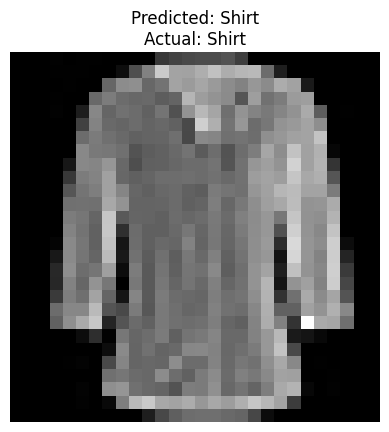

In [54]:
# Display the prediction
plt.figure()
plt.imshow(X_test[image_index], cmap="gray")
plt.title(
    f"Predicted: {class_names[predicted_label]}\n"
    f"Actual: {class_names[y_test[image_index]]}"
)
plt.axis("off")
plt.show()